# Axis 3 — Prefill Granularity & Expert Amortisation (Mac / MLX)

**Question.** Which prefill chunk size C gets the most reuse out of each expert load without blowing the memory budget?

**Hypothesis (from the team page).** As C grows from 1 to 128, TTFT drops non-linearly because tokens in the same chunk share experts (the chance that an expert loaded for one token is reused by another approaches 1). Beyond C = 128 the set of distinct experts a chunk needs exceeds the cache, forcing scratch-memory growth or evictions inside the chunk.

## Why chunking matters with an expert cache
A prefill pass over C tokens asks each layer for the *union* of the experts its C tokens route to. One load then serves many tokens (amortisation). But the pass walks all 16 layers before the next chunk starts, so the experts of one chunk across all layers must fit in K, or layer 0's experts are evicted by layer 15 before the next chunk reuses them.

## What is measured, for each (C, K)
| Metric | Meaning |
|---|---|
| TTFT | prefill of the whole prompt + first token, cold cache |
| prefill I/O | experts loaded, GB read, time in disk reads |
| reuse ratio | token→expert assignments ÷ distinct experts loaded, per layer call |
| distinct / layer call | experts one layer needs for one chunk (max 64) |
| chunk footprint | Σ over 16 layers of distinct experts per chunk, vs K |
| grouped calls | layer calls needing more experts than K: processed in groups of ≤ K (intra-chunk eviction) |
| scratch memory | MLX peak minus bank minus weights (activations, attention, KV) |

Everything is a real run on the disk-backed cache; no simulation.

**Runtime.** Full grid ≈ 40–60 min (C = 1 is slow by design). `MOE_SMOKE=1` takes a few minutes.

In [1]:
import os, sys, time, json, importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlx.core as mx

# Shared code: the `moe` package in src/. `pip install -e ".[mac]"` installs it; the path
# line below makes the notebook work without installing.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'moe').is_dir())
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from moe import common, mlx_cache as mc, results as rs, figures as fg   # mc is Mac only (MLX)
for m in (common, mc, rs, fg):
    importlib.reload(m)                # pick up edits to src/moe without restarting the kernel

# MOE_SMOKE=1 runs a tiny configuration end to end (used to test the notebook).
SMOKE = os.environ.get('MOE_SMOKE') == '1'
AXIS_DIR = ROOT / 'experiments' / 'axis-3-prefill-chunking'
RESULTS = (ROOT / 'experiments' / '.cache' / 'smoke' / 'axis-3-prefill-chunking') if SMOKE else (AXIS_DIR / 'results')
RESULTS.mkdir(parents=True, exist_ok=True)

DEVICE = 'mac'                          # results file: <axis>/results/mac.json
AXIS = 'axis-3-prefill-chunking'
TABLES = {}                             # every table this run produces, saved at the end

plt.rcParams.update({'figure.figsize': (11, 5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})
print('SMOKE run' if SMOKE else 'Full run', '| results ->', RESULTS.relative_to(ROOT))
print(mc.system_info())

Full run | results -> experiments/axis-3-prefill-chunking/results
{'chip': 'Apple M4', 'ram_GB': 17.2, 'macOS': '27.2', 'python': '3.14.8', 'mlx': '0.32.2'}


## Configuration

In [2]:
CHUNKS = [1, 4, 16, 32, 64, 128, 256, 512]     # plus 'full' = the whole prompt in one pass
K_VALUES = [128, 256, 512]
PROMPT_TOKENS = 512            # every prompt is trimmed to this many article tokens
N_PROMPTS = 2                  # long passages written for this axis (max 2)
INCLUDE_FULL = True

if SMOKE:
    CHUNKS, K_VALUES, PROMPT_TOKENS, N_PROMPTS = [8, 64], [128, 512], 128, 1

print('chunks:', CHUNKS + (['full'] if INCLUDE_FULL else []), '| K:', K_VALUES,
      '| prompt tokens:', PROMPT_TOKENS)
CONFIG = rs.config_from(globals())   # recorded in the results file

chunks: [1, 4, 16, 32, 64, 128, 256, 512, 'full'] | K: [128, 256, 512] | prompt tokens: 512


## Model and correctness gate

In [3]:
model, tokenizer, index = mc.load_model()
print(index.describe())
print(f'Non-expert weights resident: {mc.non_expert_bytes(model) / 1e9:.2f} GB '
      f'| MLX active memory: {mx.get_active_memory() / 1e9:.2f} GB')
print(f'Largest K that fits safely in this machine\'s RAM: {mc.max_safe_capacity(index)}')

# Correctness gate: one layer through the K-slot bank vs the stock mlx-lm layer
# (all 64 experts of that layer stacked). Must be bit-identical.
diff = mc.check_layer_exactness(model, index, capacity=64)
assert diff == 0.0, diff
print(f'Layer exactness vs stock mlx-lm: max |diff| = {diff}')

16 layers x 64 experts = 1024 logical experts | 12.58 MB each (F16) | full bank 12.9 GB on disk
Non-expert weights resident: 0.95 GB | MLX active memory: 0.95 GB
Largest K that fits safely in this machine's RAM: 417


Layer exactness vs stock mlx-lm: max |diff| = 0.0


## Long prompts (fixed length)
Two long passages written for this axis, each trimmed to exactly `PROMPT_TOKENS` tokens so every chunk size processes the same input.

In [4]:
# Long inputs written for this axis: prefill only matters when the prompt is long.
prompt_file = rs.load_prompts(AXIS_DIR)   # axis-3-prefill-chunking/prompts.json, shared by every device
PASSAGES = prompt_file['PASSAGES']
prompts = []
for text in PASSAGES[:N_PROMPTS]:
    ids = tokenizer.encode(text)
    assert len(ids) >= PROMPT_TOKENS, f'passage has only {len(ids)} tokens'
    prompts.append(mc.chat_tokens(tokenizer, 'Summarize the following passage in three sentences.\n\n'
                                  + tokenizer.decode(ids[:PROMPT_TOKENS])))
print('passage tokens:', [len(tokenizer.encode(t)) for t in PASSAGES],
      '| prompt lengths used (incl. chat template):', [len(t) for t in prompts])

passage tokens: [663, 642] | prompt lengths used (incl. chat template): [537, 537]


## Sweep
Fresh (cold) cache for every run, so each TTFT includes loading what the prompt needs. Pass `C = 'full'` is the whole prompt in one forward pass.

In [5]:
SAFE_K = mc.max_safe_capacity(index)
K_VALUES = [k for k in K_VALUES if k <= SAFE_K]
weights_GB = mc.non_expert_bytes(model) / 1e9
chunk_list = CHUNKS + (['full'] if INCLUDE_FULL else [])
rows, call_rows = [], []
ref_tok = {}
for K in K_VALUES:
    for C in chunk_list:
        for pi, toks in enumerate(prompts):
            mc.free_memory(); mx.reset_peak_memory()
            cache = mc.ExpertCache(index, K, 'LRU')
            rec = mc.Recorder()
            mc.attach_cache(model, cache, [rec])
            chunk = None if C == 'full' else C
            on_step = lambda ph, j: rec.set(phase=ph, chunk=j)
            r = mc.generate(model, tokenizer, toks, max_new_tokens=1, prefill_chunk=chunk, on_step=on_step)
            s = cache.summary()
            peak = mx.get_peak_memory() / 1e9
            # Chunking should not change the result (it can, rarely, by float rounding).
            ref_tok.setdefault(pi, r.tokens[0])
            same_token = r.tokens[0] == ref_tok[pi]

            ev = pd.DataFrame(rec.events)
            ev['distinct'] = ev.eids.map(len)
            ev['reuse'] = ev.n * 8 / ev.distinct
            per_chunk = ev.groupby('chunk').distinct.sum()          # experts per chunk, all layers
            n_chunks = len(per_chunk)
            rows.append({
                'K': K, 'C': C, 'C_num': len(toks) if C == 'full' else C, 'prompt': pi,
                'prompt_tokens': len(toks), 'n_passes': n_chunks, 'ttft_s': r.ttft_s,
                'misses': s['misses'], 'hit_rate': s['hit_rate'], 'GB_loaded': s['GB_loaded'],
                'io_s': s['io_ms'] / 1000, 'route_wait_s': mc.route_wait_ms(model) / 1000,
                'reuse_mean': ev.reuse.mean(), 'distinct_per_call': ev.distinct.mean(),
                'distinct_per_call_max': ev.distinct.max(), 'chunk_footprint': per_chunk.mean(),
                'chunk_footprint_max': per_chunk.max(),
                'grouped_calls': int((ev.distinct > K).sum()),
                'peak_GB': peak, 'scratch_GB': peak - s['bank_GB'] - weights_GB,
                'same_first_token': same_token,
            })
            cache.close(); del cache
            print(f'K={K:4d} C={str(C):>5s} p{pi}: TTFT {r.ttft_s:6.2f}s | {n_chunks:4d} passes | '
                  f'loads {s["misses"]:5d} ({s["GB_loaded"]:.1f} GB) | reuse {ev.reuse.mean():5.1f}x | '
                  f'footprint {per_chunk.mean():6.0f} | grouped {rows[-1]["grouped_calls"]} | '
                  f'scratch {rows[-1]["scratch_GB"]:.2f} GB')

res = pd.DataFrame(rows)
TABLES['runs'] = res
print(f'\nFirst token identical to the first run in {res.same_first_token.mean():.0%} of runs '
      '(differences would come from float rounding in chunked attention).')

K= 128 C=    1 p0: TTFT 169.37s |  537 passes | loads 45989 (578.7 GB) | reuse   1.0x | footprint    128 | grouped 0 | scratch 0.11 GB


K= 128 C=    1 p1: TTFT 167.91s |  537 passes | loads 46727 (588.0 GB) | reuse   1.0x | footprint    128 | grouped 0 | scratch 0.11 GB


K= 128 C=    4 p0: TTFT 150.63s |  135 passes | loads 46143 (580.6 GB) | reuse   1.5x | footprint    342 | grouped 0 | scratch 0.11 GB


K= 128 C=    4 p1: TTFT 160.99s |  135 passes | loads 47014 (591.6 GB) | reuse   1.5x | footprint    348 | grouped 0 | scratch 0.11 GB


K= 128 C=   16 p0: TTFT  78.22s |   34 passes | loads 22497 (283.1 GB) | reuse   3.1x | footprint    662 | grouped 0 | scratch 0.11 GB


K= 128 C=   16 p1: TTFT  80.05s |   34 passes | loads 22919 (288.4 GB) | reuse   3.0x | footprint    674 | grouped 0 | scratch 0.11 GB


... (26 outputs left out)

K= 256 C=  512 p0: TTFT  11.50s |    2 passes | loads  1877 (23.6 GB) | reuse  34.0x | footprint    938 | grouped 0 | scratch 0.19 GB


K= 256 C=  512 p1: TTFT  12.00s |    2 passes | loads  1906 (24.0 GB) | reuse  33.9x | footprint    953 | grouped 0 | scratch 0.19 GB


K= 256 C= full p0: TTFT   7.16s |    1 passes | loads  1020 (12.8 GB) | reuse  67.4x | footprint   1020 | grouped 0 | scratch 0.23 GB


K= 256 C= full p1: TTFT   6.30s |    1 passes | loads  1023 (12.9 GB) | reuse  67.2x | footprint   1023 | grouped 0 | scratch 0.23 GB

First token identical to the first run in 78% of runs (differences would come from float rounding in chunked attention).


## Results

In [6]:
g = res.groupby(['K', 'C_num']).agg(ttft_s=('ttft_s', 'mean'), GB_loaded=('GB_loaded', 'mean'),
                                     io_s=('io_s', 'mean'), reuse=('reuse_mean', 'mean'),
                                     distinct_per_call=('distinct_per_call', 'mean'),
                                     footprint=('chunk_footprint', 'mean'), grouped=('grouped_calls', 'mean'),
                                     scratch_GB=('scratch_GB', 'mean')).reset_index()
best = g.loc[g.groupby('K').ttft_s.idxmin(), ['K', 'C_num', 'ttft_s']]
print('Fastest chunk size per K:'); display(best.set_index('K'))
g.style.format({'ttft_s': '{:.2f}', 'GB_loaded': '{:.2f}', 'io_s': '{:.2f}', 'reuse': '{:.1f}',
                'distinct_per_call': '{:.1f}', 'footprint': '{:.0f}', 'grouped': '{:.0f}', 'scratch_GB': '{:.2f}'})

Fastest chunk size per K:


,C_num,ttft_s
K,,
128,537,6.383089
256,537,6.730787


,K,C_num,ttft_s,GB_loaded,io_s,reuse,distinct_per_call,footprint,grouped,scratch_GB
0,128,1,168.64,583.32,135.56,1.0,8.0,128,0,0.11
1,128,4,155.81,586.09,138.31,1.5,21.6,345,0,0.11
2,128,16,79.14,285.73,69.35,3.1,41.7,668,0,0.11
3,128,32,50.13,173.52,44.48,5.0,50.7,811,0,0.12
4,128,64,33.13,101.25,29.74,8.6,55.9,894,0,0.12
5,128,128,24.00,58.96,21.78,14.5,58.6,937,0,0.13
6,128,256,15.23,36.02,13.71,23.2,59.6,954,0,0.14
7,128,512,10.88,23.80,9.69,33.9,59.1,946,0,0.19
8,128,537,6.38,12.85,5.46,67.3,63.8,1022,0,0.23
9,256,1,159.74,475.75,127.08,1.0,8.0,128,0,0.11


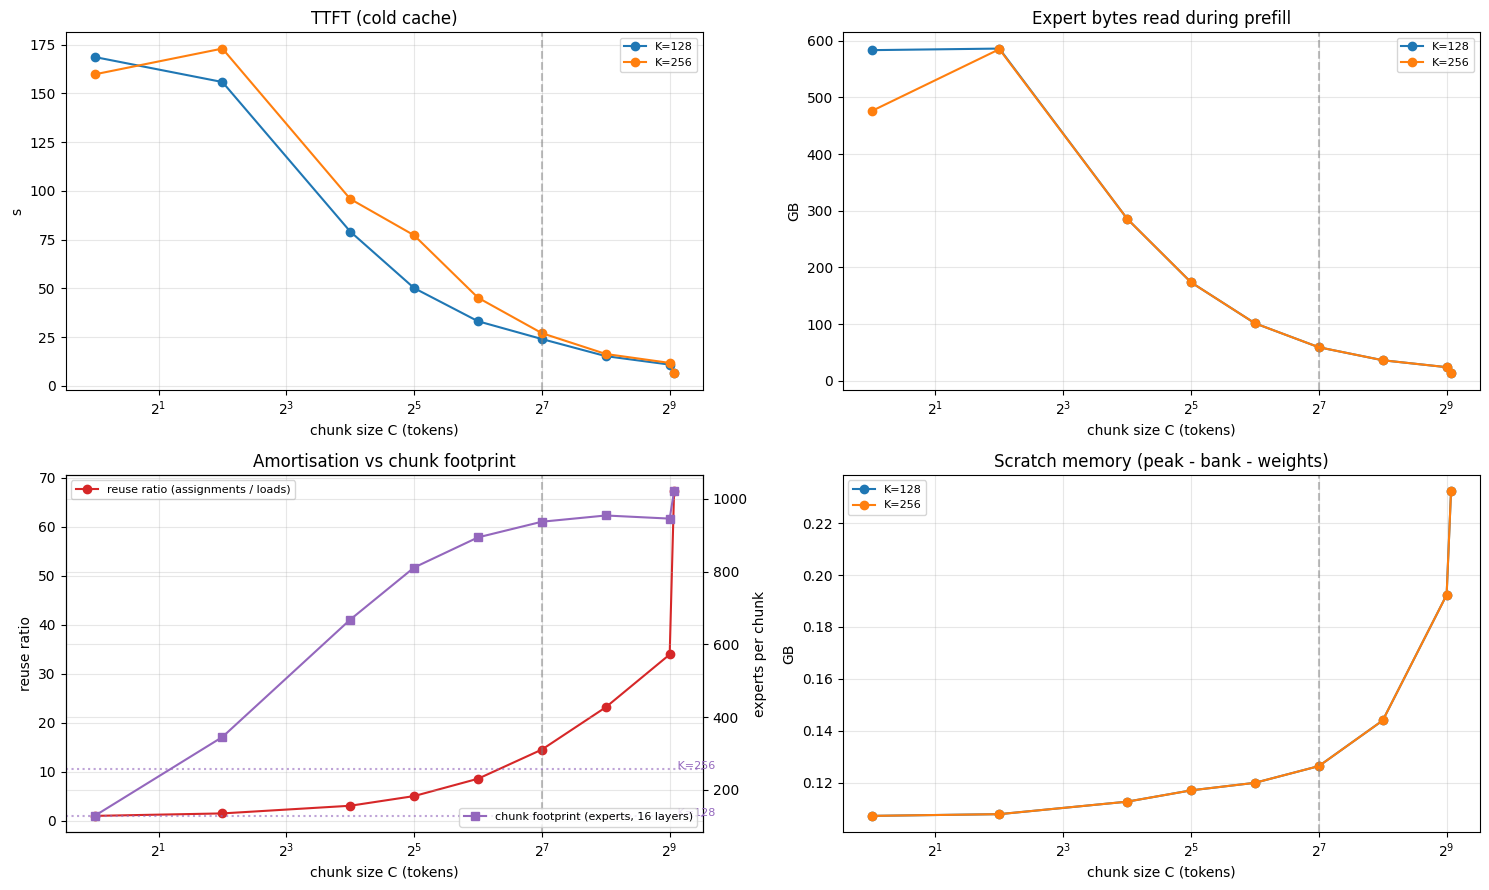

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for K, d in g.groupby('K'):
    axes[0, 0].plot(d.C_num, d.ttft_s, '-o', label=f'K={K}')
    axes[0, 1].plot(d.C_num, d.GB_loaded, '-o', label=f'K={K}')
    axes[1, 1].plot(d.C_num, d.scratch_GB, '-o', label=f'K={K}')
d0 = g[g.K == g.K.min()]
axes[1, 0].plot(d0.C_num, d0.reuse, '-o', color='C3', label='reuse ratio (assignments / loads)')
ax2 = axes[1, 0].twinx()
ax2.plot(d0.C_num, d0.footprint, '-s', color='C4', label='chunk footprint (experts, 16 layers)')
for K in g.K.unique():
    ax2.axhline(K, color='C4', ls=':', alpha=0.6); ax2.text(d0.C_num.max(), K, f' K={K}', fontsize=8, color='C4')
ax2.set_ylabel('experts per chunk'); axes[1, 0].set_ylabel('reuse ratio')
axes[1, 0].legend(loc='upper left', fontsize=8); ax2.legend(loc='lower right', fontsize=8)
titles = ['TTFT (cold cache)', 'Expert bytes read during prefill', 'Amortisation vs chunk footprint',
          'Scratch memory (peak - bank - weights)']
ylabels = ['s', 'GB', None, 'GB']
for ax, t, yl in zip(axes.flat, titles, ylabels):
    ax.set_xscale('log', base=2); ax.set_xlabel('chunk size C (tokens)'); ax.set_title(t)
    ax.axvline(128, color='grey', ls='--', alpha=0.5)
    if yl: ax.set_ylabel(yl)
for ax in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## How many distinct experts does one layer need per chunk?
If routing were uniform, a layer would need $64\,(1-(1-8/64)^C)$ distinct experts for C tokens. The measured curve shows how much faster than "uniform" real routing saturates.

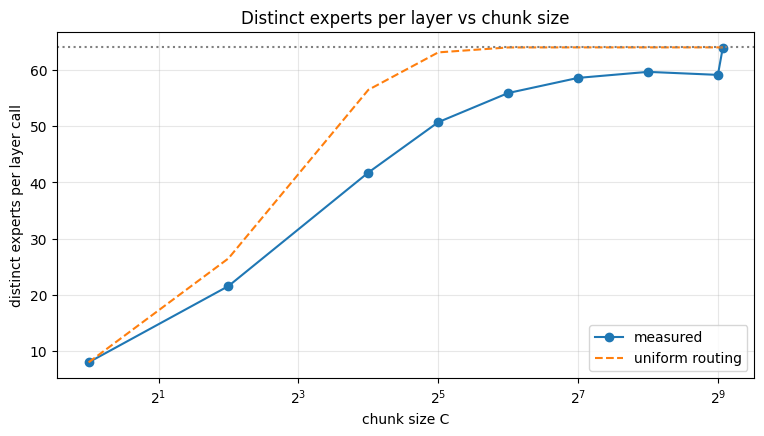

In [8]:
d0 = g[g.K == g.K.max()].sort_values('C_num')
C = d0.C_num.values
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(C, d0.distinct_per_call, '-o', label='measured')
ax.plot(C, 64 * (1 - (1 - 8 / 64) ** C), '--', label='uniform routing')
ax.axhline(64, color='grey', ls=':'); ax.set_xscale('log', base=2)
ax.set_xlabel('chunk size C'); ax.set_ylabel('distinct experts per layer call'); ax.legend()
ax.set_title('Distinct experts per layer vs chunk size')
plt.show()

## Hypothesis check (descriptive)

In [9]:
for K, d in g.groupby('K'):
    d = d.sort_values('C_num')
    t = dict(zip(d.C_num, d.ttft_s))
    c_best = int(d.loc[d.ttft_s.idxmin(), 'C_num'])
    over = d[d.footprint > K].C_num.min()
    print(f'K={K}: fastest C = {c_best} ({t[c_best]:.2f}s); '
          f'TTFT at the smallest C = {t[d.C_num.min()]:.2f}s ({t[d.C_num.min()] / t[c_best]:.1f}x slower). '
          f'Chunk footprint exceeds K from C = {over if not pd.isna(over) else "never"}; '
          f'grouped (intra-chunk-evicting) calls at the largest C: {int(d.grouped.iloc[-1])}.')
print('\nThe hypothesis predicts the fastest C near 128 and footprint > K beyond it.')

K=128: fastest C = 537 (6.38s); TTFT at the smallest C = 168.64s (26.4x slower). Chunk footprint exceeds K from C = 4; grouped (intra-chunk-evicting) calls at the largest C: 0.
K=256: fastest C = 537 (6.73s); TTFT at the smallest C = 159.74s (23.7x slower). Chunk footprint exceeds K from C = 4; grouped (intra-chunk-evicting) calls at the largest C: 0.

The hypothesis predicts the fastest C near 128 and footprint > K beyond it.


## Save results
Every table above goes into **one file for this device**: `results/mac.json`, with the configuration, prompts and machine it ran on.
The Windows notebooks write `windows-igpu.json` / `windows-dgpu.json` next to it in the same format (see `experiments/README.md`).

In [ ]:
CONFIG['SAFE_K'] = globals().get('SAFE_K')
path = rs.save(RESULTS, AXIS, DEVICE, TABLES, config=CONFIG, prompts=rs.load_prompts(AXIS_DIR),
               system=mc.system_info())
print('Saved', path.relative_to(ROOT), '| tables:', {k: len(v) for k, v in TABLES.items()})

## Cross-device figures
The report figures, drawn from every device's results file in this folder (colour = device). Only shown here;
`python -m moe.figures` writes them to `figures/` once all devices have results.

In [ ]:
figs = fg.make(AXIS, RESULTS)